Notebook built from data downloaded using 0_preprocessing_argo.ipynb

In [1]:
import warnings
warnings.filterwarnings('ignore')

import xarray as xr
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import cartopy.crs as ccrs
import cmocean.cm as cmo
import gsw
from matplotlib import ticker

from load_profiles import compute_mld_density

In [2]:
import matplotlib as mpl

mpl.rcParams['xtick.labelsize'] = 12
mpl.rcParams['ytick.labelsize'] = 12

In [3]:
def convert_hydrographic(sp, t, p, lon, lat):
    
    # SA from SP
    sa = np.zeros(sp.shape)
    for profile in range(sa.shape[0]):
        sa[profile,:] = gsw.SA_from_SP(sp[profile,:], p[profile,:], lon[profile], lat[profile])
    
    # CT from t
    ct = np.zeros(sp.shape)
    for profile in range(sa.shape[0]):
        ct[profile,:] = gsw.CT_from_t(sa[profile,:], t[profile,:], p[profile,:])
    
    # density
    sg = gsw.sigma0(sa, ct)
    
    return sa, ct, sg

def interpolate_argoprofiles(prof, period=None, convert_gsw=False):
    juld = prof.TIME.values       # time in YYYY-MM-DDTHH
    psal = prof.PSAL.values       # practical salinity values
    temp = prof.TEMP.values       # temperature values
    pres = prof.PRES.values       # pressure values
    prei = np.arange(5,255,5)     # vertical resolution of 5m
    
    # converting to TEOS-10    
    if convert_gsw:
        psal, temp, sigma = convert_hydrographic(psal, temp, pres, prof.LONGITUDE.values, prof.LATITUDE.values)
    else:
        sigma = gsw.sigma0(psal, temp)
    
    # filtering by time
    if period:
        idt = np.where( (juld >= pd.to_datetime(period[0])) & (juld <= pd.to_datetime(period[1])))
        
        juld = juld[idt[0]]
        psal = psal[idt[0]]
        pres = pres[idt[0]]
        temp = temp[idt[0]]
    
    psali= np.zeros((juld.shape[0],prei.shape[0]))
    psali.fill(np.nan)
    
    tempi= np.zeros((juld.shape[0],prei.shape[0]))
    tempi.fill(np.nan)
    
    densi= np.zeros((juld.shape[0],prei.shape[0]))
    densi.fill(np.nan)

    for ip in range(0,pres.shape[0]-1):
        psali[ip,:] = np.interp(prei,pres[ip,:],psal[ip,:])
        tempi[ip,:] = np.interp(prei,pres[ip,:],temp[ip,:])
        densi[ip,:] = np.interp(prei,pres[ip,:],sigma[ip,:])
        
    return juld, prei, psali, tempi, densi

def compute_mld_argo(juld, prei, psali, tempi, densi):
    
    lats = prof['LATITUDE'].values
    mlds = []
    for cast in range(psali.shape[0]):
        _p = prei[:]
        _sa = psali[cast,:]
        _ct = tempi[cast,:]
        _ds = densi[cast,:]

        _x = gsw.z_from_p(_p, lats[cast])
        # mld = compute_mld(_x*(-1), _sa, _ct, _ds)
        mld = compute_mld_density(_x*(-1), _ds, threshold=0.03)
        mlds.append(mld)
        
    return np.asarray(mlds)

In [4]:
def plot_transect(prof):
    # creating transect by interpolating argo profiles into a section
    # NOTE: here we don't need to convert the data again (GWS) because it was already done
    # when saving the netcdf file
    juld, prei, psali, tempi,densi = interpolate_argoprofiles(prof, None, convert_gsw=False)    

    fig, axes = plt.subplots(nrows=2, figsize=figsize, sharex=True)

    ## #___SALINITY____# ##
    ax = axes[0]
    cs=ax.contourf(juld,prei,psali.transpose(), np.linspace(36, 38, 100 + 1), cmap=cmo.haline, vmin=36, vmax=38, extend='min')

    cs2=ax.contour(juld,prei,densi.transpose(), colors=('w'), levels=[25, 25.5, 26], linewidths=(0.5), linestyles=('--'))

    cs3=ax.contour(juld,prei,psali.transpose(), colors=('k'), levels=[36.1, 37.1], linewidths=(0.5))

    ax.scatter(juld, np.ones([juld.shape[0]])*4, marker='v', c='k')

    if mld:
        mlds = compute_mld_argo(juld, prei, psali, tempi, densi)
        axes[0].plot(prof['TIME'].values[:-1], mlds[:-1], 'r', ls='--', lw=.5)
        axes[1].plot(prof['TIME'].values[:-1], mlds[:-1], 'r', ls='--', lw=.5)

    ax.invert_yaxis()
    ax.set_ylim([200,3])
    ax.set_xlim([juld[0], juld[-2]])
    ax.clabel(cs2, fmt='%2.1f', colors='w', fontsize=10)
    ax.clabel(cs3, fmt='%2.1f', colors='k', fontsize=10)

    ax.set_xlabel("")
    ax.set_ylabel("depth [m]")

    cbar_salt = fig.colorbar(cs, ax=ax, **{'pad': 0.02})
    cbar_salt.set_label(label=r'absolute salinity [$g\ kg^{-1}$]', size=12)

    ## #___ TEMPERATURE ____# ##
    ax = axes[1]
    cs=ax.contourf(juld,prei,tempi.transpose(), np.linspace(15, 31, 100 + 1), cmap=cmo.thermal, vmin=15, vmax=31)
    # cs=ax.contourf(juld,prei,psali.transpose(), np.linspace(36, 38, 100 + 1), cmap=cmo.haline, vmin=36, vmax=38, extend='min')
    cs2=ax.contour(juld,prei,densi.transpose(),colors=('w'), levels=[25, 25.5, 26], linewidths=(0.5), linestyles=('--'))
    cs3=ax.contour(juld,prei,psali.transpose(), colors=('k'), levels=[37.1], linewidths=(0.5))
    ax.scatter(juld, np.ones([juld.shape[0]])*4, marker='v', c='k')

    ax.invert_yaxis()
    ax.set_ylim([200,3])
    ax.set_xlim([juld[0], juld[-2]])
    ax.clabel(cs2, fmt='%2.1f', colors='w', fontsize=10)
    ax.clabel(cs3, fmt='%2.1f', colors='k', fontsize=10)

    ax.set_xlabel("")
    ax.set_ylabel("depth [m]")

    cbar_temp = fig.colorbar(cs, ax=ax, **{'pad': 0.02})
    cbar_temp.set_label(label=r'temperature [$^oC$]', size=12)

    # axes[1].invert_xaxis()

    ## #___ COLORBAR SETTINGS ____# ##
    tick_locator = ticker.MaxNLocator(nbins=9)
    cbar_salt.locator = tick_locator
    cbar_salt.update_ticks()

    tick_locator = ticker.MaxNLocator(nbins=8)
    cbar_temp.locator = tick_locator
    cbar_temp.update_ticks()
    
    return fig,axes

In [5]:
period = ['2022-01-01', '2022-05']
proj = ccrs.PlateCarree()
extent = [-47.5, -37.5, -28, -20.62]
depth_limits = [0, 1000]

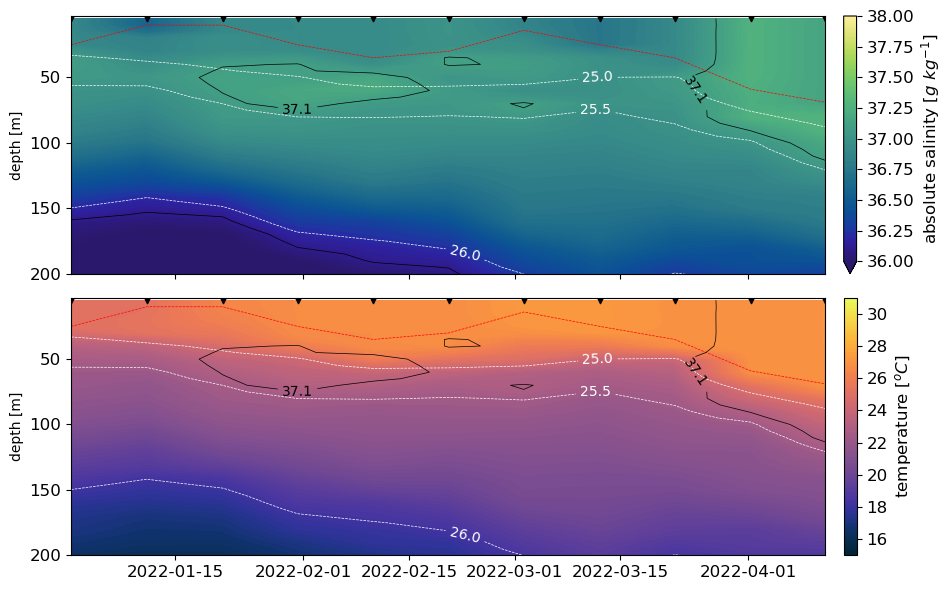

In [6]:
profID = 3901549
figsize=(10,6)
mld = True

prof = xr.open_dataset(f'../data/argo/profiles_all_{profID}.nc')

fig,axes = plot_transect(prof)

plt.tight_layout()
fig.patch.set_alpha(1.0)
plt.subplots_adjust(wspace=.1)
plt.savefig('../figures/manuscript/00_manuscript_argo_alongshelf.png', bbox_inches="tight", dpi=300)

For the second ARGO profiler, I'll do something similar to what I've done for the glider transect, slicing the transect in chunks to improve clarity in the discussion.

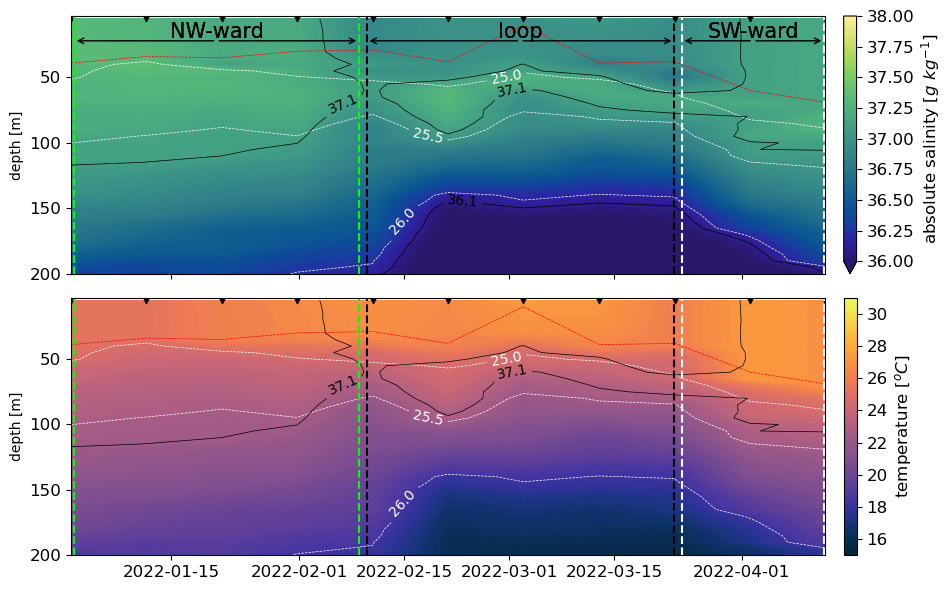

In [7]:
profID = 3901225
figsize=(10,6)
mld = True

chunks = {
    'NW-ward': ['2022-01-02', '2022-02-09', 'lime'],
    'loop': ['2022-02-10', '2022-03-23', 'k',],
    'SW-ward': ['2022-03-24', '2022-04-12', 'white']
}

prof = xr.open_dataset(f'../data/argo/profiles_all_{profID}.nc')

fig,axes = plot_transect(prof)

# adding chunks
for letter,chunk in chunks.items():
    period = [pd.to_datetime(chunk[0]), pd.to_datetime(chunk[1])]
    color = chunk[2]
    central_dt = period[0] + (period[1] - period[0]) / 2
    
    _ = [ax.axvline(period[0], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [ax.axvline(period[1], c=color, lw=1.5, ls='dashed') for ax in axes]
    _ = [axes[0].text(central_dt, 20, 
                 letter, fontsize=15, ha='center') for ax in axes]
    
    # Setas (usando annotate)
    arrowprops = dict(arrowstyle="->", color='k')
    for ax in axes[:1]:
        # Do texto ao início
        ax.annotate('', xy=(period[0], 22), xytext=(central_dt, 22), arrowprops=arrowprops)
        
        # Do texto ao fim
        ax.annotate('', xy=(period[1], 22), xytext=(central_dt, 22), arrowprops=arrowprops)

plt.tight_layout()
fig.patch.set_alpha(1.0)
plt.subplots_adjust(wspace=.1)
plt.savefig('../figures/manuscript/00_manuscript_argo_crossshelf.png', bbox_inches="tight", dpi=300)

In [21]:
prof.isel(N_PROF=slice(10,-1)).TIME.values

array(['2022-04-12T03:44:40.000000000'], dtype='datetime64[ns]')